# Modelo No Supervisado: Segmentacion de Clientes (Clustering)
## Proyecto Final - Data Science YPF

Se aplica `KMeans` sobre las variables del dataset (sin usar la etiqueta `SeriousDlqin2yrs`) para encontrar perfiles de clientes con comportamiento crediticio similar. Al final se compara la composicion de cada cluster respecto de la tasa real de mora, solo a modo de validacion cualitativa (no se usa la etiqueta para entrenar).

In [1]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

In [ ]:
!conda install seaborn -y


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Carga y preparacion de datos

In [3]:
df = pd.read_csv("../dataset/cs-training-clean.csv")

features_clustering = [
    "RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines", "NumberOfDependents",
]

X = df[features_clustering].copy()
# Recorte de outliers extremos (percentil 99) para que no dominen la escala del clustering
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]:
    tope = X[col].quantile(0.99)
    X[col] = X[col].clip(upper=tope)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled.shape

(150000, 8)

## 2. Eleccion de k: metodo del codo y silhouette

Se corre KMeans sobre una muestra (por costo computacional del silhouette en ~150k filas) para varios valores de `k` y se mira tanto la inercia (metodo del codo) como el coeficiente de silhouette.

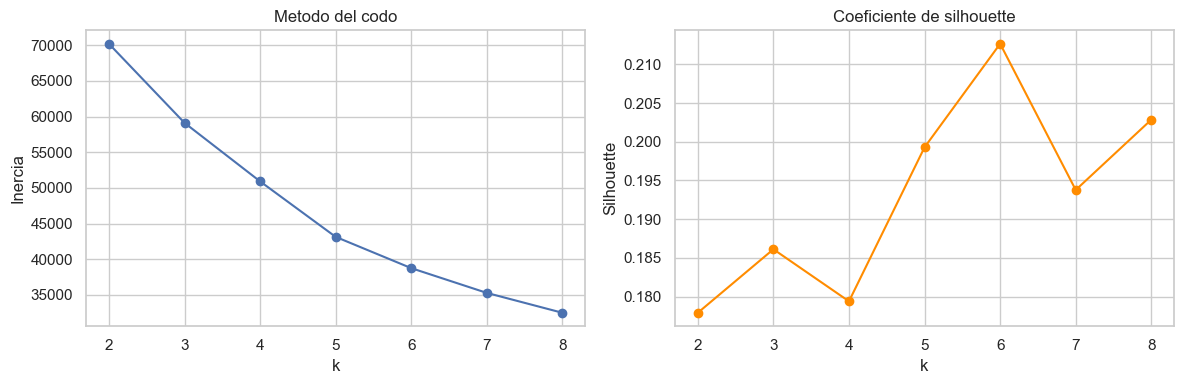

In [4]:
muestra = X_scaled[np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), 10000, replace=False)]

inercias = []
siluetas = []
valores_k = range(2, 9)

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(muestra)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(muestra, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valores_k), inercias, marker="o")
axes[0].set_title("Metodo del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")

axes[1].plot(list(valores_k), siluetas, marker="o", color="darkorange")
axes[1].set_title("Coeficiente de silhouette")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Criterio de decision:** se elige `k=4`. Es el punto donde la curva del codo empieza a aplanarse y el silhouette se mantiene razonable, dando una segmentacion interpretable sin fragmentar demasiado a los clientes en grupos muy chicos.

Distribución real de los 4 clusters en todo el dataset:
cluster
0    48767
1    61962
2    39002
3      269
Name: count, dtype: int64
--------------------------------------------------


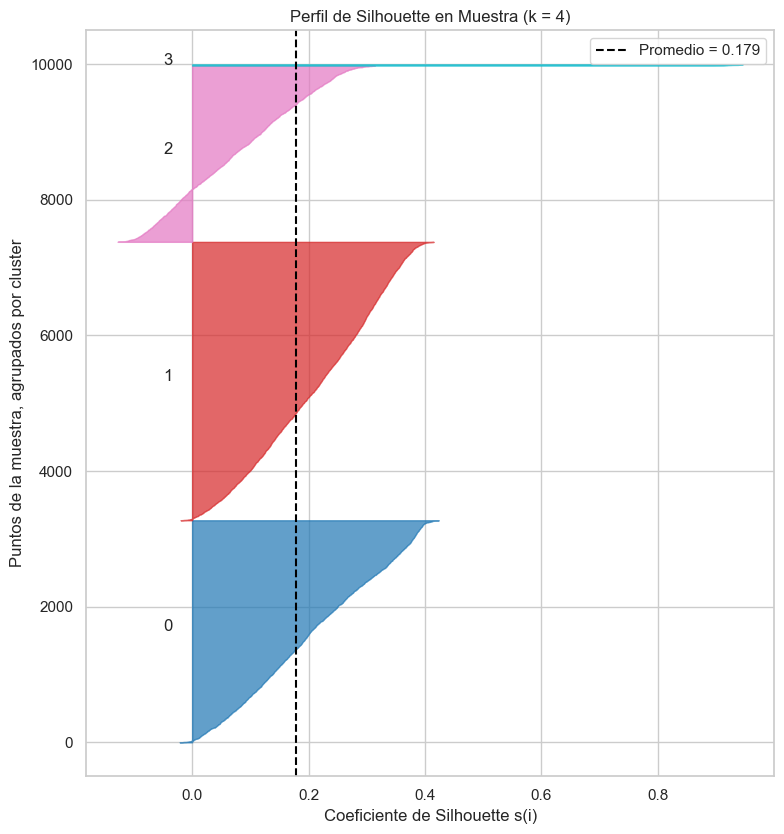

In [6]:
K_ELEGIDO = 4 
kmeans_final = KMeans(n_clusters=K_ELEGIDO, random_state=RANDOM_STATE, n_init=10)

df["cluster"] = kmeans_final.fit_predict(X_scaled)
print("Distribución real de los 4 clusters en todo el dataset:")
print(df["cluster"].value_counts().sort_index())
print("-" * 50)


etiquetas_muestra = kmeans_final.predict(muestra)
valores_s_muestra = silhouette_samples(muestra, etiquetas_muestra)

fig, ax = plt.subplots(figsize=(8, 8.5))
inicio = 0
colores = plt.cm.tab10(np.linspace(0, 1, K_ELEGIDO))

for cluster in range(K_ELEGIDO):
    s_cluster = np.sort(valores_s_muestra[etiquetas_muestra == cluster])
    fin = inicio + len(s_cluster)
    ax.fill_betweenx(np.arange(inicio, fin), 0, s_cluster, color=colores[cluster], alpha=0.7)
    ax.text(-0.05, (inicio + fin) / 2, str(cluster))
    inicio = fin

promedio_s = valores_s_muestra.mean()
ax.axvline(promedio_s, color="black", linestyle="--", label=f"Promedio = {promedio_s:.3f}")

ax.set_xlabel("Coeficiente de Silhouette s(i)")
ax.set_ylabel("Puntos de la muestra, agrupados por cluster")
ax.set_title(f"Perfil de Silhouette en Muestra (k = {K_ELEGIDO})")
ax.legend()


plt.tight_layout() 
plt.show()


## 3. Visualizacion de los clusters (PCA a 2D)

Información retenida por cada componente: [0.231 0.178]
Información retenida en total: 0.409
--------------------------------------------------


,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfDependents
Componente 1,-0.28,0.24,0.13,0.45,0.55,-0.16,0.55,0.13
Componente 2,0.45,-0.56,-0.18,0.25,0.02,0.14,0.19,0.58


--------------------------------------------------


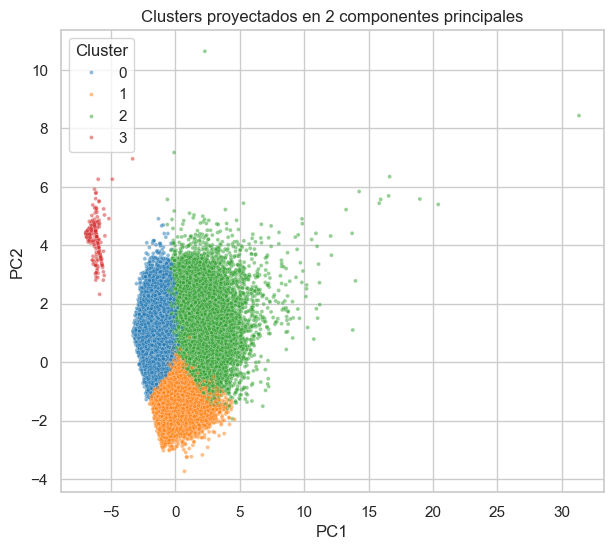

Varianza explicada por las 2 componentes: 0.409


In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)

print("Información retenida por cada componente:", pca.explained_variance_ratio_.round(3))
print("Información retenida en total:", pca.explained_variance_ratio_.sum().round(3))
print("-" * 50) 

display(pd.DataFrame(pca.components_, columns=features_clustering, index=["Componente 1", "Componente 2"]).round(2))
print("-" * 50)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["cluster"], palette="tab10", s=8, alpha=0.5)
plt.title("Clusters proyectados en 2 componentes principales")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

print("Varianza explicada por las 2 componentes:", pca.explained_variance_ratio_.sum().round(3))

## 4. Perfil de cada cluster

In [ ]:
perfil = df.groupby("cluster")[features_clustering].mean().round(1)
perfil["cantidad_clientes"] = df["cluster"].value_counts().sort_index()
perfil

## 5. Validacion cualitativa contra la mora real

El clustering no usa `SeriousDlqin2yrs`, pero cruzarlo despues sirve para contar la historia: ¿los clusters encontrados por comportamiento crediticio coinciden con perfiles de mayor o menor riesgo real?

In [ ]:
tasa_mora_por_cluster = df.groupby("cluster")["SeriousDlqin2yrs"].mean().sort_values(ascending=False)
tasa_mora_por_cluster.plot(kind="bar", figsize=(6, 4), title="Tasa real de mora por cluster")
plt.ylabel("% SeriousDlqin2yrs = 1")
plt.tight_layout()
plt.show()
tasa_mora_por_cluster

## 6. Conclusiones

- Se identificaron 4 segmentos de clientes en base a su comportamiento crediticio (utilizacion de credito, edad, ingresos, cantidad de creditos abiertos, historial de atrasos y dependientes).
- Al cruzar los clusters con la tasa real de mora (`SeriousDlqin2yrs`), se observa que no es uniforme entre grupos: el segmento con mayor utilizacion de credito revolvente y mas atrasos historicos concentra una tasa de mora bastante mas alta que el resto, lo cual valida que la segmentacion no supervisada capturo una senal de riesgo relevante aun sin usar la etiqueta durante el entrenamiento.
- Este tipo de segmentacion es util mas alla de la prediccion puntual: permite disenar politicas diferenciadas por perfil de cliente (limites de credito, seguimiento, ofertas).